# Part 2 — Nested Monte Carlo

In [Part 1](01_hierarchical_sampling.ipynb) the target was $\mathbb{E}_{z_1}\big[\mathbb{E}_{z_2\mid z_1}[\ell]\big]$.
The inner expectation entered **linearly**, so the tower property collapsed two loops into one ordinary
Monte Carlo problem.

**Nested Monte Carlo (NMC)** is the name for estimating

$$
\mathbb{E}_{z_1}\Big[\, f\big(z_1,\; \mathbb{E}_{z_2\mid z_1}[\,h(z_1, z_2)\,]\big) \Big]
\qquad\text{with } f \text{ nonlinear in its second argument.}
$$

Now the inner expectation must be estimated **before** $f$ is applied. A finite-sample estimate pushed
through a nonlinear $f$ is biased, and that changes everything: the estimator is biased, it is inconsistent
at fixed $M$, and the right way to spend a budget is completely different from Part 1.

We keep exactly the same model as Part 1 and simply move the $\log$ outside the inner expectation.

**Contents**
1. The nested target, and why it is worth estimating
2. The NMC estimator
3. Bias: always negative, monotone in $M$, asymptotically $-C/M$
4. Inconsistency at fixed $M$
5. Bias–variance trade-off and the optimal $M$ for a budget
6. Reducing the bias: Richardson extrapolation
7. Where NMC appears in machine learning
8. Takeaways

*Reference:* T. Rainforth, R. Cornish, H. Yang, A. Warrington, F. Wood,
**On Nesting Monte Carlo Estimators**, ICML 2018.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.hermite_e import hermegauss

from model import Model

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(2026)
model = Model(rho=0.5, x=1.0)

## 1. The nested target, and why it is worth estimating

Integrate the nuisance variable $z_2$ out of the likelihood:

$$
I(z_1) \;=\; p(x \mid z_1) \;=\; \mathbb{E}_{q(z_2\mid z_1)}\big[p(x\mid z_1, z_2)\big],
$$

and target the expected log of this marginal likelihood:

$$
J \;=\; \mathbb{E}_{q(z_1)}\big[\log I(z_1)\big]
  \;=\; \mathbb{E}_{q(z_1)}\Big[\log \mathbb{E}_{q(z_2\mid z_1)}\big[p(x\mid z_1,z_2)\big]\Big].
$$

This has the NMC form with $h = p(x\mid z_1,z_2)$ and $f(z_1, u) = \log u$.

**Three quantities, one chain of inequalities.** Applying Jensen's inequality ($\log$ is concave) once inside
and once outside gives

$$
\underbrace{\mathbb{E}_{z_1,z_2}\big[\log p(x\mid z_1,z_2)\big]}_{\mu\ \text{(Part 1)}}
\;\le\;
\underbrace{\mathbb{E}_{z_1}\big[\log p(x\mid z_1)\big]}_{J\ \text{(this notebook)}}
\;\le\;
\underbrace{\log \mathbb{E}_{z_1}\big[p(x\mid z_1)\big]}_{\log p(x)} .
$$

$J$ has no closed form. Because the model is two-dimensional, though, we can compute it to many digits with
nested Gauss–Hermite quadrature (`model.nested_target()`), which gives a ground truth to measure the bias of
Monte Carlo against.

In [2]:
mu = model.exact_expected_log_lik()
J = model.nested_target()
log_px = model.log_evidence()
print(f"mu       = E[log p(x|z1,z2)] = {mu:.6f}")
print(f"J        = E[log p(x|z1)]    = {J:.6f}")
print(f"log p(x)                     = {log_px:.6f}")
print("quadrature check, J with more nodes:", f"{model._outer_expectation(lambda z: model.cond_log_marginal_lik(z, 180), 120):.6f}")

mu       = E[log p(x|z1,z2)] = -3.918939
J        = E[log p(x|z1)]    = -2.208708
log p(x)                     = -1.418252
quadrature check, J with more nodes: -2.208708


## 2. The NMC estimator

The natural estimator mirrors the target, with one Monte Carlo average per expectation:

$$
\hat J_{N,M} \;=\; \frac1N\sum_{i=1}^N \log\Bigg(\underbrace{\frac1M\sum_{j=1}^M p(x\mid z_{1,i}, z_{2,ij})}_{\hat I_M(z_{1,i})}\Bigg),
\qquad z_{1,i}\sim q(z_1),\ \ z_{2,ij}\sim q(z_2\mid z_{1,i}).
$$

The sampling code is **identical** to Part 1's two-stage estimator. Only one line differs: we average
likelihoods and *then* take the log, instead of averaging log-likelihoods. (In code we use log-sum-exp so
that tiny likelihoods do not underflow.)

Note that for $M = 1$, $\log \hat I_1 = \log p(x\mid z_{1}, z_{2})$, so $\hat J_{N,1}$ is *exactly* Part 1's
estimator of $\mu$. With a single inner sample we are estimating the wrong quantity.

In [3]:
def log_mean_exp(a, axis=-1):
    a_max = a.max(axis=axis, keepdims=True)
    return np.squeeze(a_max, axis) + np.log(np.mean(np.exp(a - a_max), axis=axis))


def nmc_per_outer(model, N, M, rng, chunk=2_000_000):
    """Returns the N values log I_hat_M(z1_i); their mean is the NMC estimate J_hat_{N,M}."""
    out = np.empty(N)
    step = max(1, chunk // M)
    for s in range(0, N, step):
        z1 = model.sample_z1(min(step, N - s), rng)
        z2 = model.sample_z2_given_z1(z1, M, rng)
        out[s:s + z1.size] = log_mean_exp(model.log_lik(z1[:, None], z2))
    return out


def nmc(model, N, M, rng):
    return nmc_per_outer(model, N, M, rng).mean()


N = 100_000
for M in (1, 10, 100):
    y = nmc_per_outer(model, N, M, rng)
    print(f"M = {M:>3}, N = {N}:  J_hat = {y.mean():.4f} ± {1.96 * y.std() / np.sqrt(N):.4f}"
          f"    (J = {J:.4f}, mu = {mu:.4f})")

M =   1, N = 100000:  J_hat = -3.8835 ± 0.0627    (J = -2.2087, mu = -3.9189)
M =  10, N = 100000:  J_hat = -2.2670 ± 0.0277    (J = -2.2087, mu = -3.9189)


M = 100, N = 100000:  J_hat = -2.2068 ± 0.0255    (J = -2.2087, mu = -3.9189)


## 3. Bias: always negative, monotone in $M$, asymptotically $-C/M$

Write $b(M) = \mathbb{E}[\hat J_{N,M}] - J$. This does not depend on $N$, because the outer average is still linear.

**Sign.** $\hat I_M(z_1)$ is unbiased for $I(z_1)$, so by Jensen
$\mathbb{E}[\log \hat I_M \mid z_1] \le \log I(z_1)$. Hence $b(M) \le 0$ for every $M$.

**Monotonicity.** An average of $M$ terms is the average, over all $(M-1)$-subsets, of the subset averages.
Concavity of $\log$ then gives $b(M-1) \le b(M)$. (This is the argument Burda et al. use to show that the
IWAE bound tightens as $K$ grows. Section 7 returns to this.) The two ends are $b(1) = \mu - J$ and
$b(\infty) = 0$.

**Rate.** Expand $\log$ to second order around $I(z_1)$ (the delta method):

$$
\mathbb{E}\big[\log \hat I_M \mid z_1\big] \approx \log I(z_1) - \frac{\operatorname{Var}(\hat I_M\mid z_1)}{2\,I(z_1)^2}
\quad\Longrightarrow\quad
b(M) \approx -\frac{C}{M},\qquad
C = \mathbb{E}_{z_1}\!\left[\frac{\operatorname{Var}\big(p(x\mid z_1,z_2)\mid z_1\big)}{2\,I(z_1)^2}\right].
$$

$C$ involves only conditional moments of $p$, which we again compute by quadrature
(`model.nested_bias_constant()`).

**Measuring $b(M)$ precisely.** A plain Monte Carlo estimate of the bias is swamped by the outer variance:
$\operatorname{Var}(\log I(z_1)) \approx 17$, while the biases of interest are around $10^{-3}$. So we
use the Part 1 trick in reverse. We integrate over $z_1$ with Gauss–Hermite quadrature and use Monte Carlo
only for the inner estimator at each node. This gives the exact bias curve up to a small, controlled error.

In [4]:
C = model.nested_bias_constant()
v_inf = model.nested_outer_variance()
print(f"C = {C:.5f}     Var(log I(z1)) = {v_inf:.4f}")


def inner_stats(model, M, stat=lambda ll: log_mean_exp(ll), n_nodes=40, evals_per_node=2_000_000, rng=rng):
    """
    Quadrature over z1, Monte Carlo over the inner estimator.
    For each Gauss-Hermite node z1_k, draws K = evals_per_node // M independent inner
    estimates stat(log p(x | z1_k, z2_{1..M})), and returns, for the per-outer-sample
    quantity Y = stat(...):
        E[Y] - J (bias), Var(Y), and the Monte Carlo standard error of the bias.
    """
    t, w = hermegauss(n_nodes)
    w = w / np.sqrt(2 * np.pi)
    z1 = model.mu1 + model.s1 * t
    K = max(evals_per_node // M, 200)
    means, var_within, se2 = [], [], []
    for z in z1:
        z2 = model.sample_z2_given_z1(np.full(K, z), M, rng)
        y = stat(model.log_lik(z, z2))
        means.append(y.mean()); var_within.append(y.var(ddof=1)); se2.append(y.var(ddof=1) / K)
    means, var_within, se2 = map(np.array, (means, var_within, se2))
    EY = np.sum(w * means)
    VarY = np.sum(w * (var_within + means**2)) - EY**2       # law of total variance over z1
    return EY - J, VarY, np.sqrt(np.sum(w**2 * se2))


Ms = np.array([1, 2, 3, 5, 10, 20, 50, 100, 200])
bias, var_M, se_b = np.array([inner_stats(model, M) for M in Ms]).T
for M, b, s, v in zip(Ms, bias, se_b, var_M):
    print(f"M = {M:>4}:  b(M) = {b:+.5f} ± {2 * s:.5f}    -C/M = {-C / M:+.5f}    Var per outer sample = {v:.3f}")

C = 0.23884     Var(log I(z1)) = 16.8092


M =    1:  b(M) = -1.71039 ± 0.00201    -C/M = -0.23884    Var per outer sample = 106.923
M =    2:  b(M) = -0.44855 ± 0.00073    -C/M = -0.11942    Var per outer sample = 37.676
M =    3:  b(M) = -0.22465 ± 0.00048    -C/M = -0.07961    Var per outer sample = 27.254
M =    5:  b(M) = -0.10021 ± 0.00034    -C/M = -0.04777    Var per outer sample = 21.520
M =   10:  b(M) = -0.03720 ± 0.00027    -C/M = -0.02388    Var per outer sample = 18.499
M =   20:  b(M) = -0.01501 ± 0.00025    -C/M = -0.01194    Var per outer sample = 17.428
M =   50:  b(M) = -0.00518 ± 0.00024    -C/M = -0.00478    Var per outer sample = 16.982
M =  100:  b(M) = -0.00258 ± 0.00024    -C/M = -0.00239    Var per outer sample = 16.879
M =  200:  b(M) = -0.00125 ± 0.00024    -C/M = -0.00119    Var per outer sample = 16.839


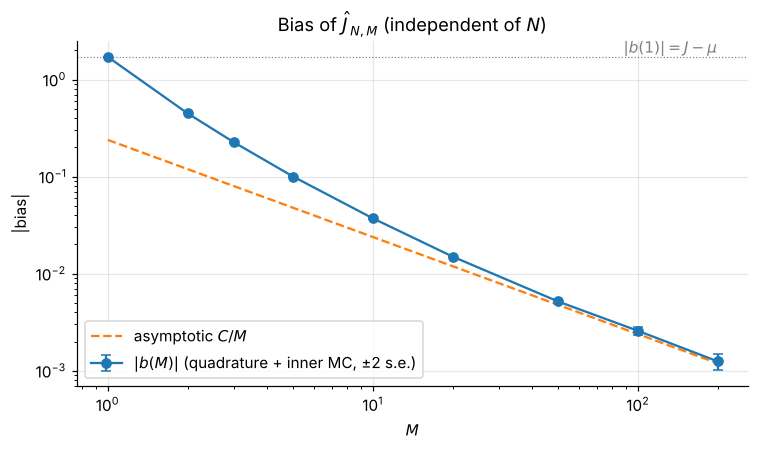

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.errorbar(Ms, -bias, yerr=2 * se_b, fmt="o-", capsize=3, label=r"$|b(M)|$ (quadrature + inner MC, ±2 s.e.)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.loglog(Ms, C / Ms, "--", label=r"asymptotic $C/M$")
ax.axhline(J - mu, color="gray", lw=0.8, ls=":")
ax.text(Ms[-1], (J - mu) * 1.1, r"$|b(1)| = J-\mu$", ha="right", color="gray")
ax.set_xlabel("$M$")
ax.set_ylabel("|bias|")
ax.set_title(r"Bias of $\hat J_{N,M}$ (independent of $N$)")
ax.legend()
plt.tight_layout()
plt.show()

Two regimes are visible:

* **Asymptotic regime** ($M \gtrsim 50$ here; beyond $M\approx 200$ the bias drops below what this computation can resolve): $b(M) \approx -C/M$, as the delta method predicts.
* **Pre-asymptotic regime** (small $M$): the bias is several times larger than $C/M$. The second-order
  expansion assumes $\hat I_M$ is concentrated around $I(z_1)$. For values of $z_1$ where
  $p(x\mid z_1, z_2)$ is dominated by rare values of $z_2$, that needs many inner samples. This is the
  same phenomenon as weight degeneracy in importance sampling.

## 4. Inconsistency at fixed $M$

For fixed $M$ the outer average is an ordinary Monte Carlo average of i.i.d. terms, so by the law of large
numbers

$$
\hat J_{N,M} \xrightarrow[N\to\infty]{\text{a.s.}} J + b(M) \;\ne\; J .
$$

More outer samples make the estimate converge **confidently to the wrong answer**. Consistency requires
$M\to\infty$ as well.

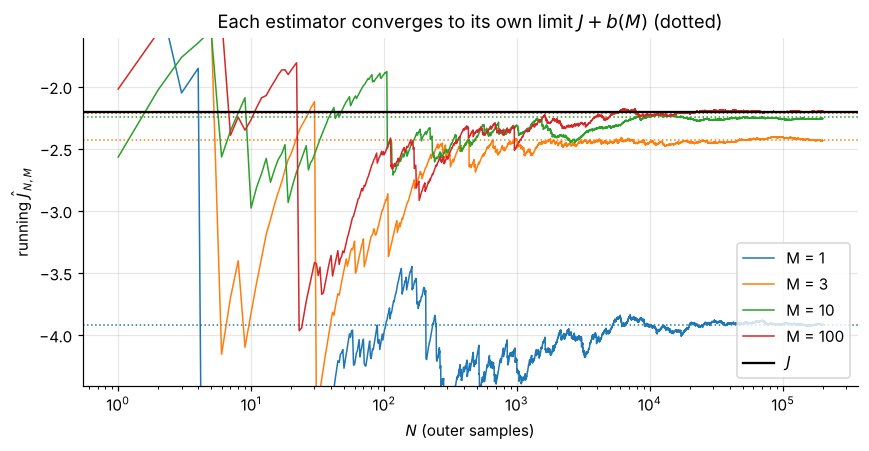

In [6]:
N_max = 200_000
fig, ax = plt.subplots(figsize=(8, 4.2))
n = np.arange(1, N_max + 1)
for k, M in enumerate((1, 3, 10, 100)):
    y = nmc_per_outer(model, N_max, M, rng)
    line, = ax.semilogx(n, np.cumsum(y) / n, lw=1, label=f"M = {M}")
    b = bias[list(Ms).index(M)]
    ax.axhline(J + b, color=line.get_color(), ls=":", lw=1)
ax.axhline(J, color="k", lw=1.5, label="$J$")
ax.set_ylim(J - 2.2, J + 0.6)
ax.set_xlabel("$N$ (outer samples)")
ax.set_ylabel(r"running $\hat J_{N,M}$")
ax.set_title("Each estimator converges to its own limit $J + b(M)$ (dotted)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Bias–variance trade-off and the optimal $M$ for a budget

Because the outer samples are i.i.d.,

$$
\operatorname{MSE}(\hat J_{N,M}) \;=\; b(M)^2 + \frac{v_M}{N},
\qquad v_M = \operatorname{Var}\big(\log \hat I_M(z_1)\big) \xrightarrow[M\to\infty]{} \operatorname{Var}\big(\log I(z_1)\big).
$$

This is an exact identity. We have both $b(M)$ and $v_M$ from Section 3.

**Asymptotic allocation.** With a budget of $T = NM$ inner evaluations, and using $b \approx -C/M$, $v_M\approx v_\infty$:

$$
\operatorname{MSE}(M) \approx \frac{C^2}{M^2} + \frac{v_\infty M}{T}
\quad\Longrightarrow\quad
M^\star = \Big(\frac{2C^2T}{v_\infty}\Big)^{1/3},\qquad
\operatorname{MSE}^\star = O\big(T^{-2/3}\big).
$$

Equivalently, $M \propto \sqrt N$. Compare Part 1, where the optimum was a *constant* $M$ (often $1$) and the
MSE fell like $T^{-1}$. **Nesting costs convergence rate:** to halve the RMSE of a nested estimator
you need about $8\times$ the budget, instead of $4\times$.

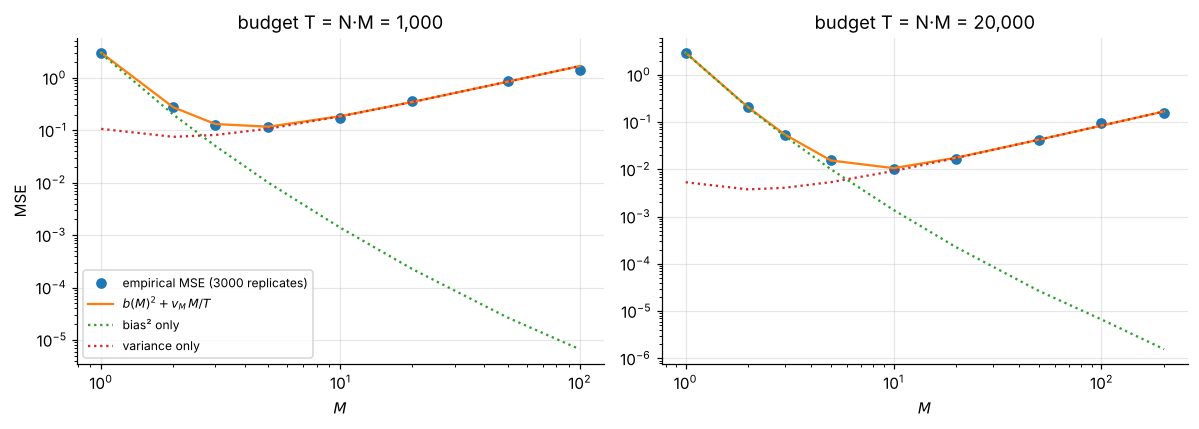

In [7]:
# Empirical check at two budgets: MSE over replicates vs  b(M)^2 + v_M M / T.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, (T, R) in zip(axes, [(1_000, 3000), (20_000, 600)]):
    M_list = [M for M in Ms if M <= T // 10]
    emp = []
    for M in M_list:
        est = np.array([nmc(model, T // M, M, rng) for _ in range(R)])
        emp.append(np.mean((est - J) ** 2))
    idx = [list(Ms).index(M) for M in M_list]
    pred = bias[idx] ** 2 + var_M[idx] * np.array(M_list) / T
    ax.loglog(M_list, emp, "o", label=f"empirical MSE ({R} replicates)")
    ax.loglog(M_list, pred, "-", label=r"$b(M)^2 + v_M\,M/T$")
    ax.loglog(M_list, bias[idx] ** 2, ":", label="bias² only")
    ax.loglog(M_list, var_M[idx] * np.array(M_list) / T, ":", label="variance only")
    ax.set_title(f"budget T = N·M = {T:,}")
    ax.set_xlabel("$M$")
axes[0].set_ylabel("MSE")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

With $b(M)$ and $v_M$ in hand, the best achievable MSE for each budget follows directly. Beyond
$M = 1000$ we use the asymptotic forms. The fitted slope is close to $-2/3$:

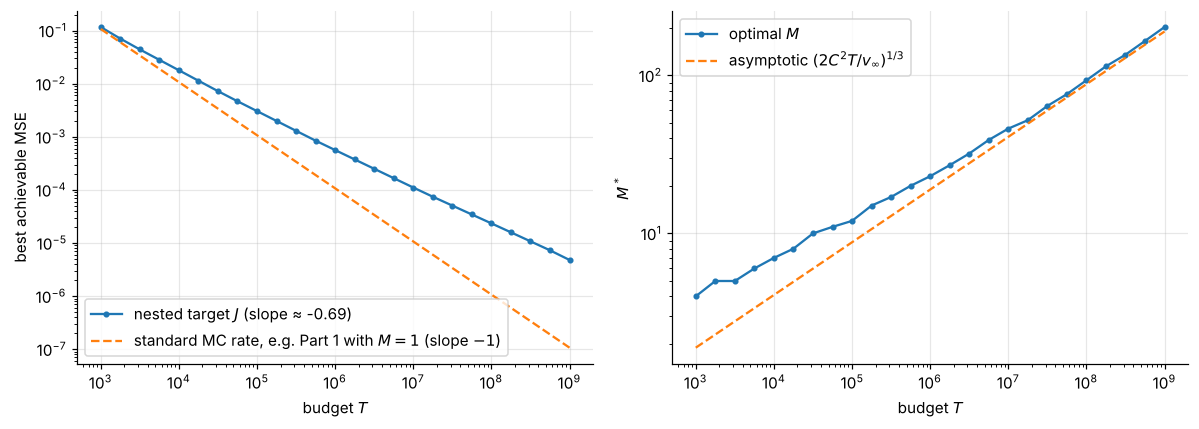

In [8]:
Ts = np.logspace(3, 9, 25)
M_big = np.unique(np.round(np.logspace(0, 5, 400)).astype(int))
# interpolate log|b| linearly in log M on the measured grid, asymptotic form beyond it
b_big = np.where(M_big <= Ms[-1], -np.exp(np.interp(np.log(M_big), np.log(Ms), np.log(-bias))), -C / M_big)
v_big = np.where(M_big <= Ms[-1], np.interp(np.log(M_big), np.log(Ms), var_M), v_inf)
best_mse, best_M = [], []
for T in Ts:
    ok = M_big <= T
    mse = b_big[ok] ** 2 + v_big[ok] * M_big[ok] / T
    best_mse.append(mse.min()); best_M.append(M_big[ok][mse.argmin()])
best_mse, best_M = np.array(best_mse), np.array(best_M)
slope = np.polyfit(np.log(Ts[10:]), np.log(best_mse[10:]), 1)[0]

vc = model.variance_components()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(Ts, best_mse, "o-", ms=3, label=f"nested target $J$ (slope ≈ {slope:.2f})")
axes[0].loglog(Ts, vc["total"] / Ts, "--", label=r"standard MC rate, e.g. Part 1 with $M=1$ (slope $-1$)")
axes[0].set_xlabel("budget $T$"); axes[0].set_ylabel("best achievable MSE"); axes[0].legend()
axes[1].loglog(Ts, best_M, "o-", ms=3, label="optimal $M$")
axes[1].loglog(Ts, (2 * C**2 * Ts / v_inf) ** (1 / 3), "--", label=r"asymptotic $(2C^2T/v_\infty)^{1/3}$")
axes[1].set_xlabel("budget $T$"); axes[1].set_ylabel("$M^*$"); axes[1].legend()
plt.tight_layout()
plt.show()

For moderate budgets the optimal $M$ sits *above* the asymptotic formula, because the pre-asymptotic bias is
larger than $C/M$. The $T^{1/3}$ growth takes over as $T$ increases.

## 6. Reducing the bias: Richardson extrapolation

Since $b(M) = -C/M + O(1/M^2)$, combining two inner sample sizes cancels the leading term:

$$
\hat J^{\text{RE}}_{N,M} = \frac1N \sum_{i=1}^N \Big( 2\log\hat I_{2M}(z_{1,i}) - \log \hat I_{M}(z_{1,i}) \Big),
\qquad b^{\text{RE}}(M) = O(1/M^2),
$$

where $\hat I_M$ reuses the first $M$ of the $2M$ inner samples, so no new samples are drawn. In general the
price is extra variance, because the correction term is itself noisy. This idea, applied over a whole ladder of levels, is the basis of **multilevel Monte Carlo**
(Giles) and of the randomised **unbiased** estimators of Rhee and Glynn.

In [9]:
def richardson(ll):
    M2 = ll.shape[-1]
    return 2 * log_mean_exp(ll) - log_mean_exp(ll[..., : M2 // 2])


print(" 2M  |  plain b(2M)   |  Richardson b   |  Var per outer: plain / RE")
for M in (5, 10, 25, 50, 100):
    b_p, v_p, _ = inner_stats(model, 2 * M)
    b_r, v_r, s_r = inner_stats(model, 2 * M, stat=richardson)
    print(f"{2 * M:>4} | {b_p:+.5f}      | {b_r:+.5f} ± {2 * s_r:.5f} | {v_p:.2f} / {v_r:.2f}")

 2M  |  plain b(2M)   |  Richardson b   |  Var per outer: plain / RE


  10 | -0.03738      | +0.02650 ± 0.00044 | 18.50 / 16.61


  20 | -0.01503      | +0.00671 ± 0.00037 | 17.43 / 16.60


  50 | -0.00533      | +0.00133 ± 0.00035 | 16.98 / 16.75


 100 | -0.00267      | +0.00069 ± 0.00034 | 16.88 / 16.79


 200 | -0.00102      | +0.00023 ± 0.00034 | 16.84 / 16.81


Reading the table:
* At small $M$ the expansion behind Richardson does not hold yet, and the correction **overshoots**: the bias
  flips sign and is not smaller in magnitude.
* From $2M \approx 50$ on, the bias shrinks by a factor of about 4 at no extra sampling cost. At $2M = 200$
  what remains is already within the resolution of this computation (±2 s.e.).
* Here the variance per outer sample is not inflated, because it is dominated by the outer term
  $\operatorname{Var}(\log I(z_1))$, which both estimators share.

So bias reduction works, but only once you are in the asymptotic regime. The same caveat applies to MLMC.

## 7. Where NMC appears in machine learning

* **Importance-weighted autoencoders.** The IWAE objective
  $\mathcal{L}_K = \mathbb{E}\big[\log \tfrac1K\sum_k p(x,z_k)/q(z_k\mid x)\big]$ is the inner part of $\hat J$:
  a log of an unbiased $K$-sample average. Section 3's facts become the IWAE facts: $\mathcal{L}_K\le\log p(x)$,
  the gap shrinks monotonically, and it shrinks like $O(1/K)$. In VI the bias *is* the object of interest,
  namely a family of tightening lower bounds.
* **Bayesian experimental design.** The expected information gain
  $\mathbb{E}_{\theta, y}\big[\log p(y\mid\theta) - \log \mathbb{E}_{\theta'}[p(y\mid\theta')]\big]$ has a log of an
  expectation inside an expectation. NMC is the textbook estimator, with exactly the $M\propto\sqrt N$ allocation.
* **Marginal likelihoods of hierarchical models**, **conditional risk measures** in finance (e.g. the probability that
  an expected loss exceeds a threshold, where $f$ is an indicator), and **expected value of partial perfect
  information** in decision analysis are all nested expectations of the same shape.

A useful habit: before nesting, check whether $f$ is linear. If it is, the tower property applies and you
are back in Part 1, with no bias and the standard $T^{-1}$ rate.

## 8. Takeaways

| | Part 1: hierarchical sampling | Part 2: nested Monte Carlo |
|---|---|---|
| Target | $\mathbb{E}_{z_1}\big[\mathbb{E}_{z_2\mid z_1}[h]\big]$ | $\mathbb{E}_{z_1}\big[f\big(\mathbb{E}_{z_2\mid z_1}[h]\big)\big]$, $f$ nonlinear |
| Collapses to single MC? | Yes (tower property) | No |
| Bias | $0$ for every $M$ | $b(M) \approx -C/M$ (for $f=\log$: always $\le 0$) |
| Fixed $M$, $N\to\infty$ | Consistent | Converges to $J + b(M)$ |
| Why $M>1$? | Only to save on expensive outer draws | Required for consistency |
| Optimal $M$ for budget $T$ | Constant: $\sqrt{(c_1/c_2)(\sigma_W^2/\sigma_B^2)}$ | Grows: $\propto T^{1/3}$ (i.e. $M\propto\sqrt N$) |
| Best MSE | $O(T^{-1})$ | $O(T^{-2/3})$ |

Same two loops in the code, very different statistics. The difference is entirely in **where the
nonlinearity sits**.

### References
* T. Rainforth, R. Cornish, H. Yang, A. Warrington, F. Wood. *On Nesting Monte Carlo Estimators.* ICML 2018.
* Y. Burda, R. Grosse, R. Salakhutdinov. *Importance Weighted Autoencoders.* ICLR 2016.
* M. B. Giles. *Multilevel Monte Carlo methods.* Acta Numerica, 2015.
* C.-H. Rhee, P. W. Glynn. *Unbiased Estimation with Square Root Convergence for SDE Models.* Operations Research, 2015.
* C. P. Robert, G. Casella. *Monte Carlo Statistical Methods*, 2nd ed., Springer, 2004 (Rao–Blackwellisation).